# E-PRIOR: bad, neutral, and good location priors
### Paper-ready experiment description

Paper figures 16. Saved results are shown by default; enable the switches below to recompute.

In [1]:
from pathlib import Path
import os
if not Path("WERM").is_dir() and Path("../WERM").is_dir():
    os.chdir("..")
assert Path("WERM").is_dir(), "Open this notebook from the repository root."
from paper_support import show_panels
RUN_EXPERIMENTS = False
REGENERATE_FIGURES = False
REGENERATE_FIGURES = REGENERATE_FIGURES or RUN_EXPERIMENTS

if REGENERATE_FIGURES:
    import numpy as np, pickle, time, logging
    import matplotlib.pyplot as plt
    from IPython.display import display
    main_logger = logging.getLogger("paper")
    Path("figures").mkdir(exist_ok=True)


In [2]:
if RUN_EXPERIMENTS:
    import os
    os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
    os.environ.setdefault('OMP_NUM_THREADS', '1')
    os.environ.setdefault('MKL_NUM_THREADS', '1')
    from pathlib import Path
    from time import perf_counter
    import pickle
    import numpy as np
    import matplotlib.pyplot as plt
    from joblib import Parallel, delayed, parallel_config
    from scipy.special import comb
    from WERM.estimators import weighted_erm
    from WERM.gof import chgpt_gof_dp
    plt.switch_backend('module://matplotlib_inline.backend_inline')
    plt.rcParams.update({'font.family': 'serif', 'font.size': 13, 'axes.labelsize': 18, 'axes.titlesize': 18, 'legend.fontsize': 14, 'xtick.labelsize': 14, 'ytick.labelsize': 14, 'axes.spines.top': False, 'axes.spines.right': False})
    RESULTS_DIR = Path('results')
    RESULTS_DIR.mkdir(exist_ok=True)
    N_TRIALS = 100
    N_JOBS = 36
    SEED = 20260916
    P = 100
    N = 500
    NOISE_SD = 0.5
    M = lambda prediction, truth: 0.5 * (np.asarray(prediction) - np.asarray(truth)) ** 2

    def make_paired_data(trial, true_cp):
        """Identical X, y and signals across methods within trial."""
        rng = np.random.default_rng(np.random.SeedSequence([SEED, trial]))
        delta = N / P
        beta = np.empty((P, len(true_cp) + 1))
        beta[:, 0] = rng.normal(size=P) * np.sqrt(delta)
        for segment in range(1, beta.shape[1]):
            beta[:, segment] = beta[:, segment - 1] + 1.5 * np.sqrt(delta) * rng.normal(size=P)
        X = rng.normal(size=(N, P)) / np.sqrt(N)
        signal = np.searchsorted(true_cp, np.arange(N), side='right')
        y = np.einsum('ij,ij->i', X, beta[:, signal].T) + rng.normal(0, NOISE_SD, N)
        return (X, y, beta, signal)

    def error_metrics(cp, truth):
        """Normalized symmetric nearest-neighbor loss, defined even at the empty set.

        U(A,B) = 0.5*[mean_a min_b |a-b|/n + mean_b min_a |a-b|/n]
                 + 0.25*||A|-|B||/max(1,|A|,|B|).
        Missing-direction distance is 1. Hausdorff is reported only for nonempty B.
        """
        (a, b) = (np.asarray(truth, int), np.asarray(cp, int))
        if b.size:
            pair = np.abs(a[:, None] - b[None, :]) / N
            directed_a = float(pair.min(axis=1).mean())
            directed_b = float(pair.min(axis=0).mean())
            haus = float(max(pair.min(axis=1).max(), pair.min(axis=0).max()))
        else:
            directed_a = directed_b = 1.0
            haus = np.nan
        count_penalty = 0.25 * abs(len(a) - len(b)) / max(1, len(a), len(b))
        return dict(count=len(b), empty=len(b) == 0, conditional_haus=haus, exact_count_haus=haus if len(a) == len(b) else np.nan, unconditional_loss=0.5 * (directed_a + directed_b) + count_penalty)

    def conditional_coefficient_mse(X, beta, true_signal, phi):
        """Exact E_noise[mean((B_hat-B_true)^2) | X,B_true] for this weighted LS fit.

        B_hat_l = A_l y, A_l=(X'W_l X)^(-1) X'W_l. Thus the conditional
        expectation is squared bias plus noise_sd^2 * ||A_l||_F^2. This is an
        exact finite-sample coefficient prediction, not a CP-risk theorem.
        """
        from scipy.linalg import cho_factor, cho_solve
        mu = np.einsum('ij,ij->i', X, beta[:, true_signal].T)
        total = 0.0
        for (l, weight) in enumerate(phi):
            w = weight / weight.sum()
            gram = X.T @ (w[:, None] * X)
            right = X.T * w
            try:
                A = cho_solve(cho_factor(gram, lower=True, check_finite=False), right, check_finite=False)
            except np.linalg.LinAlgError:
                A = np.linalg.pinv(gram) @ right
            bias = A @ mu - beta[:, l]
            total += float(bias @ bias + NOISE_SD ** 2 * np.sum(A * A))
        return total / beta.shape[0] / beta.shape[1]

    def population_prediction(beta, true_signal, phi, delta_n):
        """Conditional population-risk comparator for the *same* weighted fixed-L ERM.

        With X_i~N(0,I/n), E[w_i (y_i-X_i b)^2] is minimized at
        b_l = sum_i phi[l,i] beta_{s(i)} / sum_i phi[l,i].
        The expected per-time GOF is 0.5*(noise_sd^2+||beta_s-b_l||^2/n).
        This is a population prediction, NOT a finite-sample theorem or fixed-point
        prediction. It uses the identical phi, L, loss, and partition search.
        """
        L = phi.shape[0]
        row_mass = phi.sum(axis=1)
        mixture = np.column_stack([np.bincount(true_signal, weights=phi[l], minlength=beta.shape[1]) / row_mass[l] for l in range(L)])
        beta_pop = beta @ mixture
        risk = np.empty((N, L))
        for l in range(L):
            squared = np.sum((beta[:, true_signal].T - beta_pop[:, l]) ** 2, axis=1) / N
            risk[:, l] = 0.5 * (NOISE_SD ** 2 + squared)
        result = chgpt_gof_dp(lambda column, unused: column, risk, np.zeros(N), N, L, delta_n, L_is_upper_bound=False)
        return (result['changepoints'], beta_pop)
    TRUE_CP = np.rint(N * np.array([0.3, 0.55])).astype(int)
    L = 3
    DELTA_N = 25
    GOOD_SUPPORT_GAP = 0.04
    PRIORS = ('Neutral', 'Good', 'Bad')
    ARTIFACT = RESULTS_DIR / 'E_PRIOR_jointconfigs_actualgap_100paired_seed20260916.pkl'

    def admissible_pairs(n, delta_n):
        (first, second) = np.triu_indices(n - 1, k=delta_n)
        return np.column_stack((first + 1, second + 1))

    def in_window(index, center, half_width=1 / 8, trim_left=0, trim_right=0):
        return (index / N >= center - half_width + trim_left) & (index / N < center + half_width - trim_right)

    def marginalize_joint_prior(configs, n):
        """Integrate a uniform joint prior on eta=(cp1,cp2) to P(signal=l at i)."""
        if len(configs) == 0:
            raise ValueError('prior has no admissible configurations')
        phi = np.zeros((3, n + 1), dtype=float)
        mass = 1.0 / len(configs)
        np.add.at(phi[0], 0, mass * len(configs))
        np.add.at(phi[0], configs[:, 0], -mass)
        np.add.at(phi[1], configs[:, 0], mass)
        np.add.at(phi[1], configs[:, 1], -mass)
        np.add.at(phi[2], configs[:, 1], mass)
        np.add.at(phi[2], n, -mass * len(configs))
        phi = np.cumsum(phi[:, :n], axis=1)
        assert np.all(phi >= -1e-12) and np.allclose(phi.sum(axis=0), 1, atol=1e-10)
        assert np.all(phi.sum(axis=1) > 0)
        return np.clip(phi, 0, 1)
    ALL_CONFIGS = admissible_pairs(N, DELTA_N)
    first_ok = in_window(ALL_CONFIGS[:, 0], 0.3)
    first_good = in_window(ALL_CONFIGS[:, 0], 0.3, trim_right=GOOD_SUPPORT_GAP / 2)
    second_good = in_window(ALL_CONFIGS[:, 1], 0.55, trim_left=GOOD_SUPPORT_GAP / 2)
    second_bad = in_window(ALL_CONFIGS[:, 1], 0.8)
    assert not np.any(second_good & second_bad)
    CONFIGS = {'Neutral': ALL_CONFIGS, 'Good': ALL_CONFIGS[first_good & second_good], 'Bad': ALL_CONFIGS[first_ok & second_bad]}
    assert (CONFIGS['Good'][:, 1].min() - CONFIGS['Good'][:, 0].max()) / N >= GOOD_SUPPORT_GAP
    PHI = {name: marginalize_joint_prior(configs, N) for (name, configs) in CONFIGS.items()}
    assert all((np.allclose(phi.sum(axis=0), 1) for phi in PHI.values()))
    EFFECTIVE_N = {name: phi.sum(axis=1) ** 2 / (phi ** 2).sum(axis=1) for (name, phi) in PHI.items()}
    assert all((np.all(ess > P) for ess in EFFECTIVE_N.values())), 'A prior leaves a weighted fit effectively underdetermined; increase n or reduce p'

    def run_trial(trial):
        (X, y, beta, signal) = make_paired_data(trial, TRUE_CP)
        output = {}
        for name in PRIORS:
            phi = PHI[name]
            tic = perf_counter()
            (cp, beta_hat) = weighted_erm(X, y, M, L=L, Delta_n=DELTA_N, gamma=0.0, L_is_upper_bound=False, return_B_hat=True, marginal_weights=phi, coefficient_loss='least_squares', coefficient_penalty='none')
            elapsed = perf_counter() - tic
            assert len(cp) == L - 1
            (theory_cp, beta_pop) = population_prediction(beta, signal, phi, DELTA_N)
            output[name] = dict(cp=np.asarray(cp), runtime=elapsed, coefficient_mse=float(np.mean((beta_hat - beta) ** 2)), conditional_expected_coefficient_mse=conditional_coefficient_mse(X, beta, signal, phi), population_cp=theory_cp, population_loss=error_metrics(theory_cp, TRUE_CP)['unconditional_loss'], population_coefficient_bias=float(np.mean((beta_pop - beta) ** 2)), **error_metrics(cp, TRUE_CP))
        return output
    with parallel_config(backend='loky', inner_max_num_threads=1):
        trials = Parallel(n_jobs=N_JOBS, verbose=10)((delayed(run_trial)(t) for t in range(N_TRIALS)))
    assert len(trials) == N_TRIALS
    with ARTIFACT.open('wb') as handle:
        pickle.dump(dict(trials=trials, configs=CONFIGS, marginals=PHI, params=dict(N=N, P=P, true_cp=TRUE_CP, L=L, delta_n=DELTA_N, n_trials=N_TRIALS, n_jobs=N_JOBS, seed=SEED, windows='half-open; first center=.30; good second=.55; bad second=.80; width=1/4; good gap=.04', theory_kind='conditional population risk under identical fixed-L estimator')), handle)


## Updated consistent plots

In [3]:
if REGENERATE_FIGURES:
    from tools.consistent_plotting import *
    plt.close("all")


### Bad, neutral and good priors

In [4]:
if REGENERATE_FIGURES:
    saved = load_saved('results/E_PRIOR_jointconfigs_actualgap_100paired_seed20260916.pkl')
    (trials, params) = (saved['trials'], saved['params'])
    n = params['N']
    names = ['Bad', 'Neutral', 'Good']
    colors = ['#EE6677', '#4477AA', '#228833']
    truth = np.asarray(params['true_cp']) / n
    groups = [[row[name]['conditional_haus'] for row in trials] for name in names]
    for (name, values) in zip(names, groups):
        pass
    pools = [np.concatenate([np.asarray(row[name]['cp']) / n for row in trials]) for name in names]
    histogram_grid([pools], names, colors, truth, 'prior_estimated_locations', density_label_x=0.015)
    plt.close("all")


### Compact prior panels for the paper

In [5]:
if REGENERATE_FIGURES:
    from pathlib import Path
    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib.ticker import MaxNLocator
    import tools.consistent_plotting as prior_style
    prior_style.OUTPUT_DIR = Path('results/consistent_plots_20261102/E_PRIOR/compact_paper')
    prior_style.SOURCE_HASHES.clear()
    prior_style.FIGURE_AUDIT.clear()
    prior_saved = prior_style.load_saved('results/E_PRIOR_jointconfigs_actualgap_100paired_seed20260916.pkl')
    prior_n = prior_saved['params']['N']
    prior_truth = np.asarray(prior_saved['params']['true_cp']) / prior_n
    prior_names = ('Bad', 'Neutral', 'Good')
    prior_colors = ('#EE6677', '#4477AA', '#228833')
    with plt.rc_context(prior_style.PAPER_STYLE):
        (fig, axes) = plt.subplots(2, 3, figsize=(5.9, 2.4), sharex=True, sharey='row')
        fig.subplots_adjust(left=0.12, right=0.985, bottom=0.17, top=0.89, wspace=0.18, hspace=0.2)
        for (column, (name, color)) in enumerate(zip(prior_names, prior_colors)):
            configs = np.asarray(prior_saved['configs'][name], int)
            mass = np.bincount(configs.ravel(), minlength=prior_n) / (2 * len(configs))
            np.testing.assert_allclose(mass.sum(), 1)
            axes[0, column].plot(np.arange(1, prior_n) / prior_n, mass[1:], color=color, lw=1.3)
            axes[0, column].set_title(name, pad=3)
            axes[0, column].tick_params(axis='x', bottom=False)
            axes[0, column].yaxis.set_major_locator(MaxNLocator(3))
            marginal = np.asarray(prior_saved['marginals'][name])
            np.testing.assert_allclose(marginal.sum(axis=0), 1, atol=1e-08)
            for (signal, line_style) in enumerate(('-', '--', ':')):
                axes[1, column].plot(np.arange(prior_n) / prior_n, marginal[signal], color=color, ls=line_style, lw=1.3, label=f'$\\pi_i^{{({signal + 1})}}$')
            axes[1, column].set_ylim(-0.04, 1.04)
            axes[1, column].set_yticks([0, 0.5, 1])
            for ax in axes[:, column]:
                for change in prior_truth:
                    ax.axvline(change, color='black', ls='--', lw=0.75, alpha=0.65)
                ax.set_xlim(-0.02, 1.02)
                ax.set_xticks([0, 0.5, 1], ['0', '0.5', '1'])
        axes[0, 0].set_ylabel('Prior prob.')
        axes[1, 0].set_ylabel('Sample weight')
        axes[1, -1].legend(fontsize=7, loc='center right', handlelength=1.8, handletextpad=0.5, labelspacing=0.2)
        fig.supxlabel('Fractional location', x=0.55, y=0.025, fontsize=10.5)
        prior_style.export_plot(fig, 'pooled_prior_and_marginals_compact', 'Exact prior masses (top) and signal weights (bottom), in a compact shared-axis grid.')
    prior_groups = [[row[name]['conditional_haus'] for row in prior_saved['trials']] for name in prior_names]
    with plt.rc_context({**prior_style.PAPER_STYLE, 'axes.labelsize': 16, 'xtick.labelsize': 13, 'ytick.labelsize': 13}):
        (fig, ax) = plt.subplots(figsize=(2.9, 2.05))
        fig.subplots_adjust(left=0.32, right=0.98, bottom=0.24, top=0.97)
        prior_jitter = np.random.default_rng(42)
        for (position, (values, color)) in enumerate(zip(prior_groups, prior_colors)):
            prior_style.box_group(ax, values, position, color, prior_jitter, width=0.55, jitter=0.16)
        ax.set_xticks(np.arange(3), prior_names)
        ax.set_xlim(-0.55, 2.55)
        ax.set_ylabel('Hausdorff dist. / $n$', y=0.4)
        ax.yaxis.set_major_locator(MaxNLocator(4))
        prior_style.export_plot(fig, 'prior_location_box_compact', 'Saved paired Hausdorff errors, with labels sized for the compact side-by-side paper layout.')
    prior_style.verify_sources()
    plt.close("all")


## Figure 16

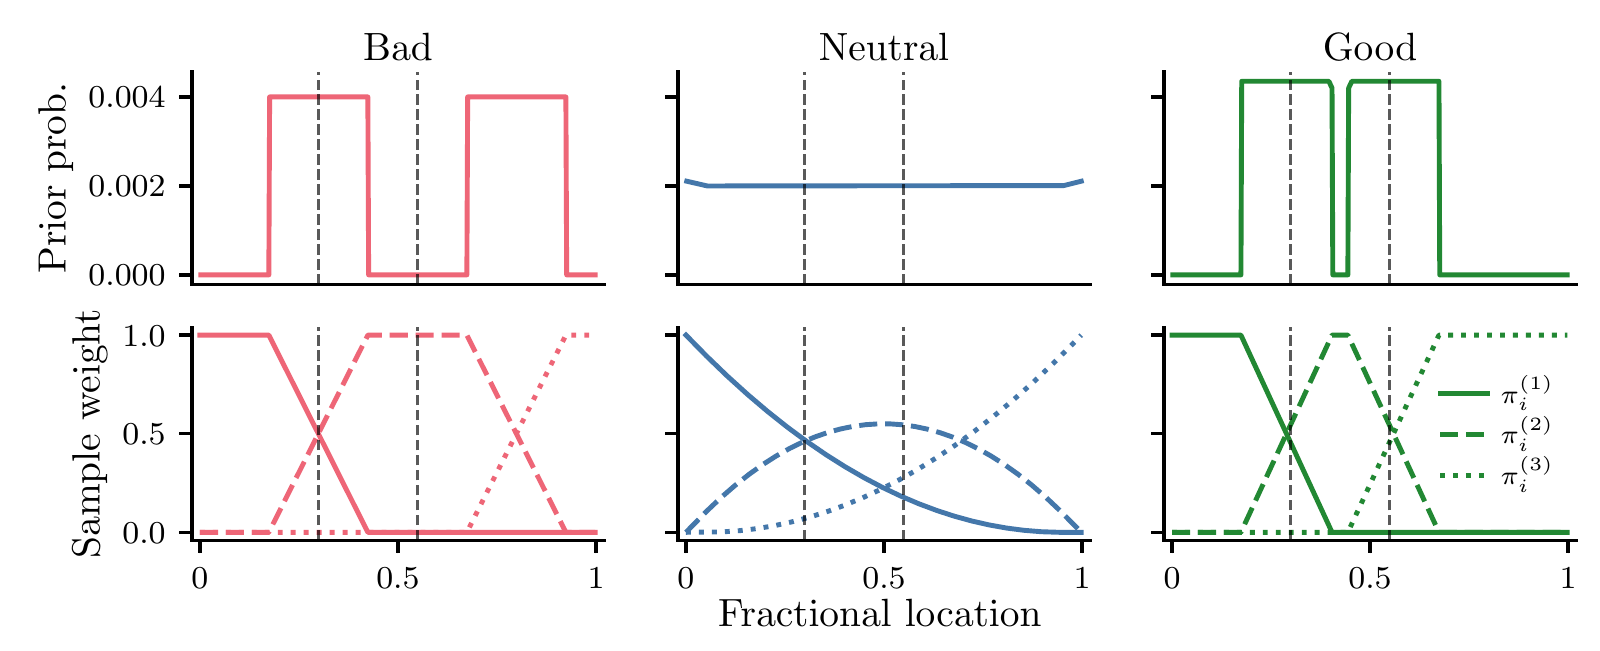

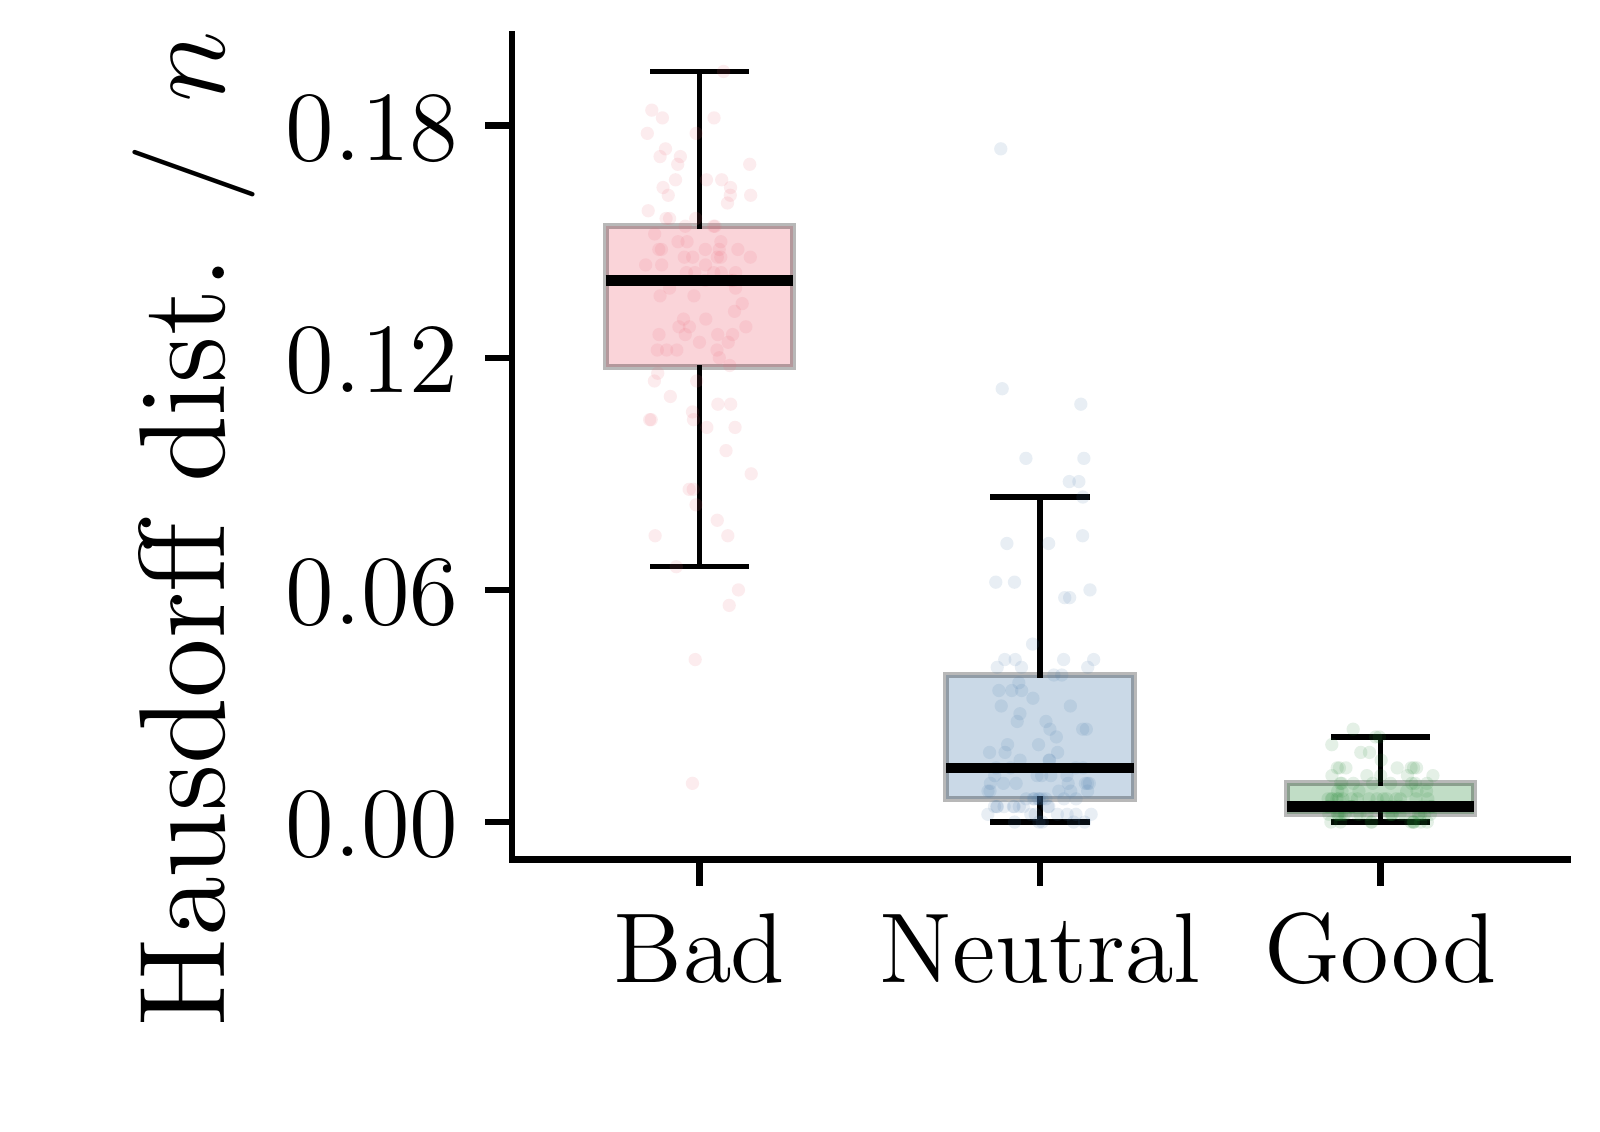

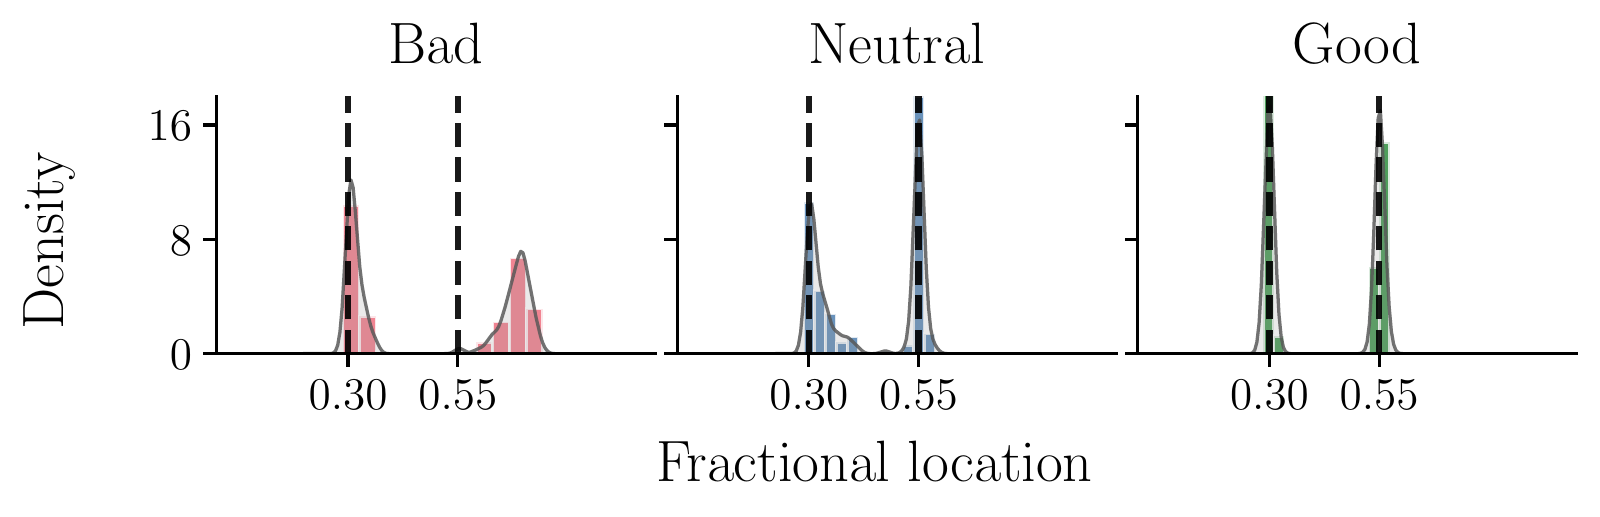

In [6]:
panels = ['results/consistent_plots_20261102/E_PRIOR/compact_paper/pooled_prior_and_marginals_compact.pdf', 'results/consistent_plots_20261102/E_PRIOR/compact_paper/prior_location_box_compact.pdf', 'figures/regenerated/prior_estimated_locations.pdf'] if REGENERATE_FIGURES else ['figures/figure_16/panel_01.pdf', 'figures/figure_16/panel_02.pdf', 'figures/figure_16/panel_03.pdf']
show_panels(panels)
